# Minimum Temperature of Melbourne EDA

Explore daily minimum temperatures from 1981 to 1990. This notebook focuses on
understanding and checking the data before building a forecasting model.


## Table of Contents

1. [Introduction](#introduction)
2. [Acquiring and Loading Data](#acquiring-and-loading-data)
3. [Data Preprocessing](#data-preprocessing)
4. [Data Analysis](#data-analysis)
5. [Conclusion](#conclusion)
6. [Epilogue](#epilogue)


<a id="introduction"></a>
## 1. Introduction

### Project Description

**Goal:** Understand the temperature patterns and data quality issues that matter
when predicting tomorrow's minimum temperature from previous days.

**Questions:**

- Are any values, dates, or records missing or duplicated?
- How do temperatures change throughout the year and across years?
- How closely is today's temperature related to earlier temperatures?

**Scope:** Descriptive analysis only. Keep the observations in date order,
inspect unusual values, and avoid inventing temperatures for missing dates.
Model training and evaluation belong in a later notebook.

### Data Description

The CSV contains 3,650 observations from January 1, 1981 to December 31, 1990.

| Original column | Description |
| :--- | :--- |
| `Date` | Observation date, written as YYYY-MM-DD |
| `Temp` | Daily minimum temperature in degrees Celsius |

**Source:** The dataset linked in the exercise, hosted in
[Jason Brownlee's Datasets repository](https://github.com/jbrownlee/Datasets/blob/master/daily-min-temperatures.csv).
A local copy is included in `data/` so rerunning the analysis does not need a download.


<a id="acquiring-and-loading-data"></a>
## 2. Acquiring and Loading Data

### Importing Libraries and Notebook Setup

Run the notebook from the repository folder. If a package is missing, install
the packages in `requirements.txt` in your notebook's Python environment.


In [1]:
from pathlib import Path
import calendar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

plt.rcParams.update({
    'figure.figsize': (12, 4),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.2,
})


### Loading Data


In [2]:
data_path = Path('data/daily-min-temperatures.csv')
raw_df = pd.read_csv(data_path)

print(f'Rows: {raw_df.shape[0]:,}')
print(f'Columns: {raw_df.shape[1]}')
raw_df.head()


Rows: 3,650
Columns: 2


,Date,Temp
0,1981-01-01,20.70
1,1981-01-02,17.90
2,1981-01-03,18.80
3,1981-01-04,14.60
4,1981-01-05,15.80


In [3]:
raw_df.tail()


,Date,Temp
3645,1990-12-27,14.00
3646,1990-12-28,13.60
3647,1990-12-29,13.50
3648,1990-12-30,15.70
3649,1990-12-31,13.00


### Basic Data Exploration

#### Check Data Types


In [4]:
raw_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3650 non-null   str    
 1   Temp    3650 non-null   float64
dtypes: float64(1), str(1)
memory usage: 57.2 KB


`Date` is loaded as text and needs to become a datetime column.
`Temp` is already numeric. We will rename both columns to make later code easier to read.


#### Check Missing Values


In [5]:
missing_values = pd.DataFrame({
    'missing_count': raw_df.isna().sum(),
    'missing_percent': raw_df.isna().mean() * 100,
})
missing_values


,missing_count,missing_percent
Date,0,0.00
Temp,0,0.00


There are no empty cells. This check alone cannot reveal dates that are absent
from the file; we check the calendar after converting the dates.


#### Check Duplicate Rows and Dates


In [6]:
print(f'Duplicate rows: {raw_df.duplicated().sum()}')
print(f'Duplicate dates: {raw_df["Date"].duplicated().sum()}')


Duplicate rows: 0
Duplicate dates: 0


#### Check Uniqueness and Data Range


In [7]:
raw_df.nunique().rename('unique_values').to_frame()


,unique_values
Date,3650
Temp,229


In [8]:
raw_df['Temp'].describe().to_frame('temperature_c')


,temperature_c
count,3650.00
mean,11.18
std,4.07
min,0.00
25%,8.30
50%,11.00
75%,14.00
max,26.30


Each date should be unique, but repeated temperatures are normal.
Recorded temperatures range from 0.0 to 26.3 degrees Celsius.

### Areas to Fix

- Rename `Date` and `Temp` to clear, consistent column names.
- Convert dates to datetime and confirm temperatures are numeric.
- Sort by date and check calendar coverage.
- Inspect unusually high or low values before deciding whether to remove anything.
- Keep both original columns: neither is redundant.


<a id="data-preprocessing"></a>
## 3. Data Preprocessing

### Rename Columns and Change Data Types

Work on a copy so the original loaded data stays available for comparison.


In [9]:
df = raw_df.rename(columns={
    'Date': 'date',
    'Temp': 'temperature',
}).copy()

df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d')
df['temperature'] = pd.to_numeric(df['temperature'], errors='raise')
df = df.sort_values('date').reset_index(drop=True)

assert pd.api.types.is_datetime64_any_dtype(df['date'])
assert pd.api.types.is_numeric_dtype(df['temperature'])
assert df['date'].is_monotonic_increasing
df.head()


,date,temperature
0,1981-01-01,20.70
1,1981-01-02,17.90
2,1981-01-03,18.80
3,1981-01-04,14.60
4,1981-01-05,15.80


### Duplicate Checks

The source has no duplicate records or dates, so no rows need to be removed.
Keep repeated temperature values recorded on different dates.


In [10]:
assert not df.duplicated().any()
assert df['date'].is_unique
print('All dates are unique.')


All dates are unique.


### Handling Missing Values and Missing Dates


In [11]:
all_dates = pd.date_range(df['date'].min(), df['date'].max(), freq='D')
missing_dates = all_dates.difference(df['date'])

print(f'Expected calendar days: {len(all_dates):,}')
print(f'Recorded days: {len(df):,}')
print(f'Missing dates: {len(missing_dates)}')
missing_dates.to_frame(index=False, name='missing_date')


Expected calendar days: 3,652
Recorded days: 3,650
Missing dates: 2


,missing_date
0,1984-12-31
1,1988-12-31


December 31, 1984 and December 31, 1988 are missing from the CSV.
Leave the observed data unchanged. For time-based calculations, use a separate
daily series with `NaN` on those dates. This keeps a one-day lag equal to one
calendar day and avoids treating observations across a gap as adjacent days.


In [12]:
daily_temperature = df.set_index('date')['temperature'].asfreq('D')

assert df[['date', 'temperature']].notna().all().all()
assert daily_temperature.isna().sum() == len(missing_dates)
print('No observed temperatures were filled or removed.')


No observed temperatures were filled or removed.


### Handling Unusual Data Ranges

Use the interquartile range (IQR) to flag values for inspection.
A flagged temperature is not automatically an error.


In [13]:
q1 = df['temperature'].quantile(0.25)
q3 = df['temperature'].quantile(0.75)
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

unusual_days = df.loc[
    (df['temperature'] < lower_limit) | (df['temperature'] > upper_limit)
]

print(f'IQR limits: {lower_limit:.2f} to {upper_limit:.2f} degrees Celsius')
print(f'Flagged observations: {len(unusual_days)}')
unusual_days


IQR limits: -0.25 to 22.55 degrees Celsius
Flagged observations: 13


,date,temperature
14,1981-01-15,25.00
17,1981-01-18,24.80
39,1981-02-09,25.00
381,1982-01-17,24.00
384,1982-01-20,25.20
403,1982-02-08,22.70
409,1982-02-14,22.80
410,1982-02-15,26.30
1425,1984-11-26,24.30
2495,1987-11-02,23.00


The flagged observations occur in November, December, January, and February. We have no evidence that these
readings are recording errors, so we keep them. Zero degrees Celsius is also
retained as a recorded temperature, rather than treated as a missing-value code.


### Feature Engineering for Exploration

Add calendar labels for grouping and plotting. These labels do not change the
recorded temperatures. No scaling is needed for EDA.


In [14]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
month_names = [calendar.month_abbr[month] for month in range(1, 13)]

df.head()


,date,temperature,year,month
0,1981-01-01,20.70,1981,1
1,1981-01-02,17.90,1981,1
2,1981-01-03,18.80,1981,1
3,1981-01-04,14.60,1981,1
4,1981-01-05,15.80,1981,1


<a id="data-analysis"></a>
## 4. Data Analysis

### Daily Temperatures Over Time

A trailing 30-day average makes the slower seasonal pattern easier to see.
The average skips missing values within each window.


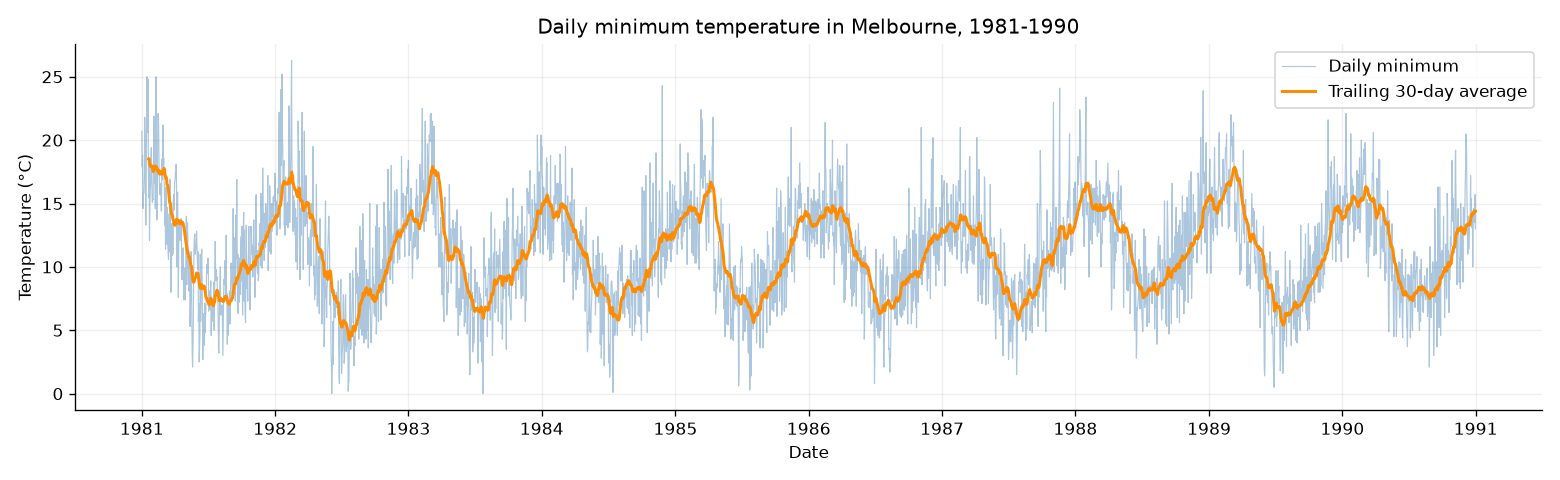

In [15]:
rolling_mean = daily_temperature.rolling(window=30, min_periods=20).mean()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily_temperature.index, daily_temperature,
        color='steelblue', alpha=0.45, linewidth=0.7, label='Daily minimum')
ax.plot(rolling_mean.index, rolling_mean,
        color='darkorange', linewidth=1.8, label='Trailing 30-day average')
ax.set(title='Daily minimum temperature in Melbourne, 1981-1990',
       xlabel='Date', ylabel='Temperature (°C)')
ax.legend()
fig.tight_layout()
plt.show()


**Observations:** Temperatures rise and fall in a repeating yearly pattern.
Daily readings fluctuate considerably around that pattern. The plot suggests
strong annual seasonality, rather than purely random variation.


### Temperature Distribution


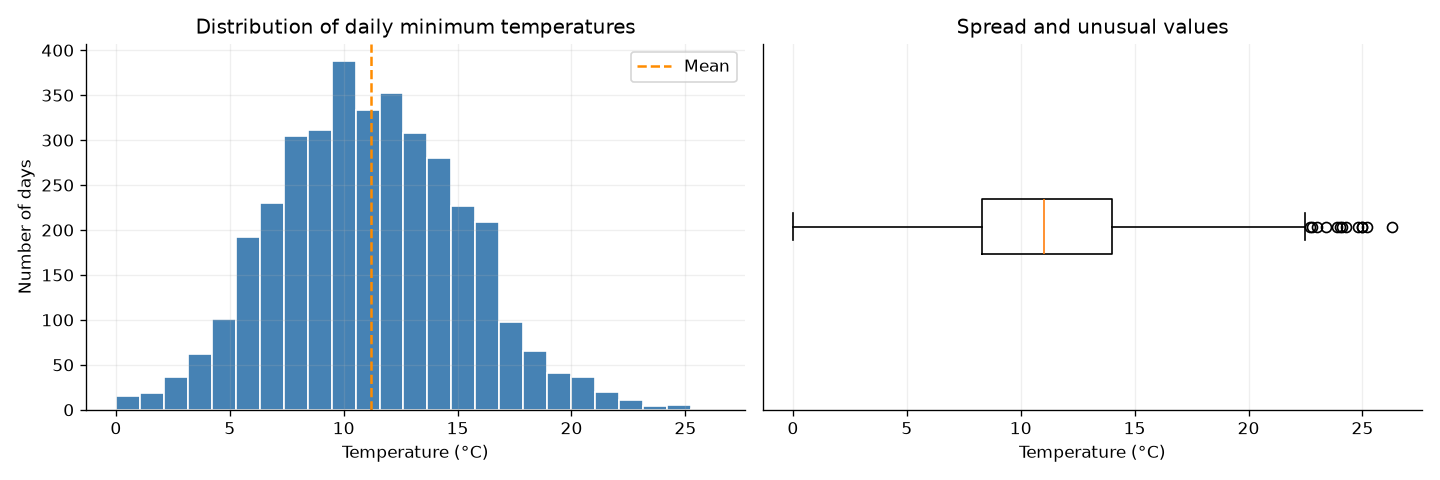

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['temperature'], bins=25, color='steelblue', edgecolor='white')
axes[0].axvline(df['temperature'].mean(), color='darkorange',
                linestyle='--', label='Mean')
axes[0].set(title='Distribution of daily minimum temperatures',
            xlabel='Temperature (°C)', ylabel='Number of days')
axes[0].legend()

axes[1].boxplot(df['temperature'], orientation='horizontal')
axes[1].set(title='Spread and unusual values', xlabel='Temperature (°C)')
axes[1].set_yticks([])

fig.tight_layout()
plt.show()


**Observations:** The mean is about 11.18°C and the median is 11.00°C.
The middle half of the readings lie between 8.3°C and 14.0°C.
The boxplot flags several high readings, which we retain for the reasons above.


### Monthly Seasonality


In [17]:
monthly_summary = df.groupby('month')['temperature'].agg(
    mean='mean', median='median', minimum='min', maximum='max', days='count'
)
monthly_summary.index = month_names
monthly_summary.index.name = 'month'
monthly_summary


,mean,median,minimum,maximum,days
month,,,,,
Jan,15.03,14.80,8.50,25.20,310
Feb,15.37,15.05,9.20,26.30,282
Mar,14.57,14.30,7.40,22.40,310
Apr,12.09,11.95,5.70,21.80,300
May,9.87,10.00,2.10,16.50,310
Jun,7.28,7.45,0.00,13.00,300
Jul,6.69,7.00,0.00,13.00,310
Aug,7.89,8.00,1.70,14.30,310
Sep,8.98,8.90,3.00,19.20,300


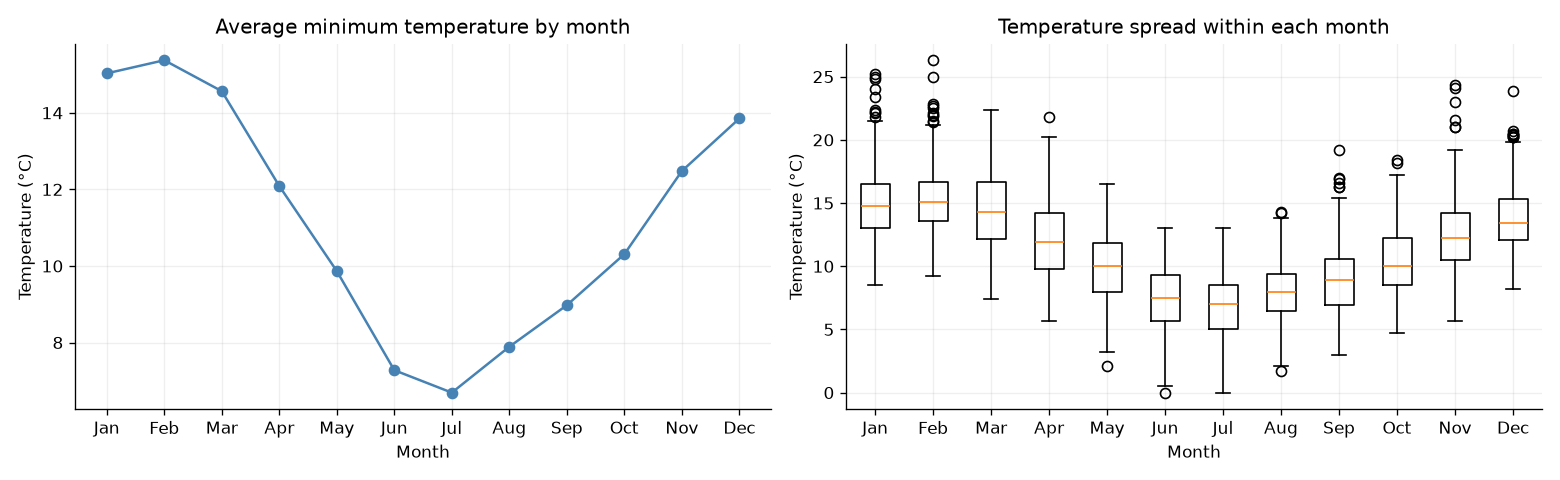

In [18]:
monthly_values = [
    df.loc[df['month'] == month, 'temperature']
    for month in range(1, 13)
]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(month_names, monthly_summary['mean'], marker='o', color='steelblue')
axes[0].set(title='Average minimum temperature by month',
            xlabel='Month', ylabel='Temperature (°C)')

axes[1].boxplot(monthly_values, tick_labels=month_names)
axes[1].set(title='Temperature spread within each month',
            xlabel='Month', ylabel='Temperature (°C)')

fig.tight_layout()
plt.show()


**Observations:** February has the highest monthly mean (about 15.37°C),
while July has the lowest (about 6.69°C). This matches Melbourne's Southern
Hemisphere seasons: warmer around December-February and colder around June-August.
The boxes also show substantial variation within each month.


### Year-to-Year Changes


In [19]:
yearly_summary = df.groupby('year')['temperature'].agg(
    mean='mean', minimum='min', maximum='max', days='count'
)
yearly_summary


,mean,minimum,maximum,days
year,,,,
1981,11.52,2.10,25.00,365
1982,10.78,0.00,26.30,365
1983,11.19,0.00,22.50,365
1984,10.59,0.10,24.30,365
1985,11.14,0.30,22.40,365
1986,10.80,0.80,21.40,365
1987,10.85,1.50,24.10,365
1988,11.97,2.80,23.90,365
1989,11.26,0.50,22.00,365


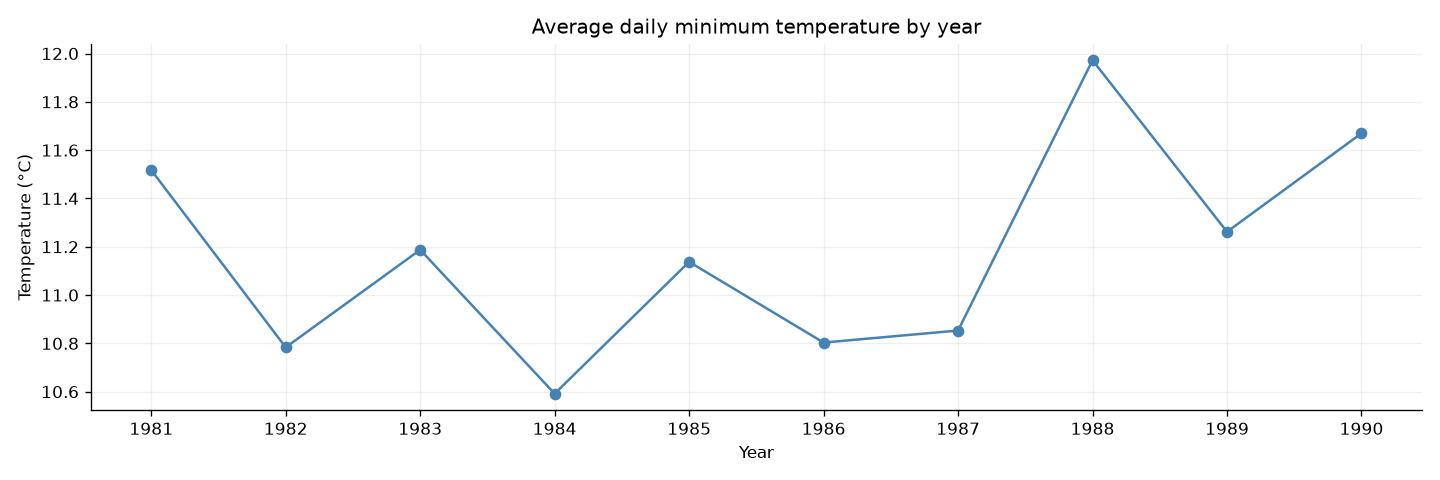

In [20]:
fig, ax = plt.subplots()
ax.plot(yearly_summary.index, yearly_summary['mean'], marker='o', color='steelblue')
ax.set(title='Average daily minimum temperature by year',
       xlabel='Year', ylabel='Temperature (°C)')
ax.set_xticks(yearly_summary.index)
fig.tight_layout()
plt.show()


**Observations:** Annual means range from about 10.59°C in 1984 to 11.97°C
in 1988. They do not increase or decrease steadily. Annual seasonality is clearer
than a long-term trend in these plots; ten years of data are not enough here to
establish a broader climate trend or a separate multi-year cycle.


### Relationship with Previous Days

Compare temperatures using calendar-day lags.


In [21]:
lag_data = daily_temperature.to_frame('today')
for lag in [1, 7, 30, 365]:
    lag_data[f'lag_{lag}'] = daily_temperature.shift(lag)

lag_correlations = lag_data.corr()['today'].drop('today')
lag_correlations.rename('correlation_with_today').to_frame()


,correlation_with_today
lag_1,0.77
lag_7,0.58
lag_30,0.48
lag_365,0.53


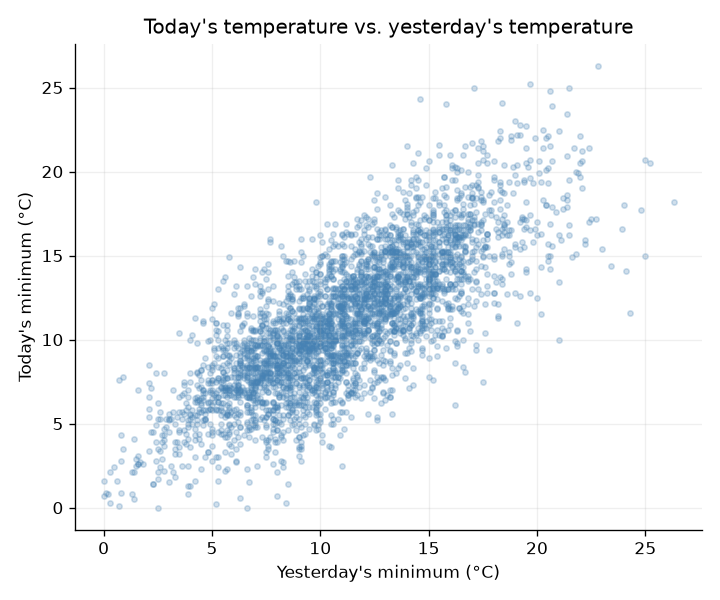

In [22]:
previous_day = lag_data[['lag_1', 'today']].dropna()

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(previous_day['lag_1'], previous_day['today'],
           s=10, alpha=0.25, color='steelblue')
ax.set(title="Today's temperature vs. yesterday's temperature",
       xlabel="Yesterday's minimum (°C)", ylabel="Today's minimum (°C)")
fig.tight_layout()
plt.show()


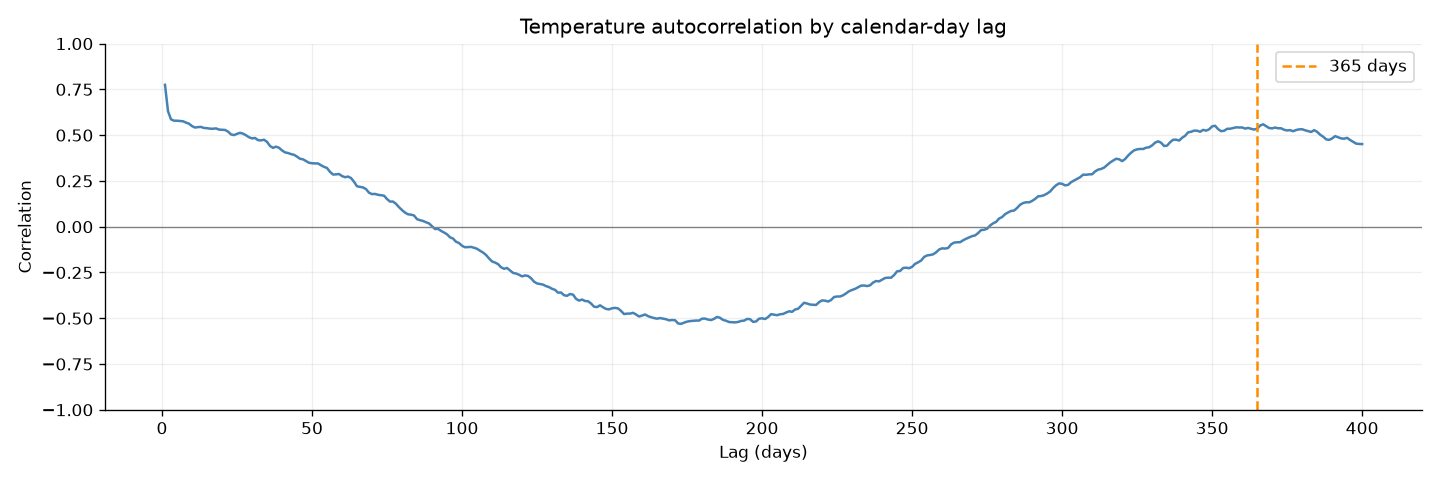

In [23]:
lags = np.arange(1, 401)
autocorrelations = [daily_temperature.autocorr(lag=int(lag)) for lag in lags]

fig, ax = plt.subplots()
ax.plot(lags, autocorrelations, color='steelblue')
ax.axhline(0, color='grey', linewidth=0.8)
ax.axvline(365, color='darkorange', linestyle='--', label='365 days')
ax.set(title='Temperature autocorrelation by calendar-day lag',
       xlabel='Lag (days)', ylabel='Correlation', ylim=(-1, 1))
ax.legend()
fig.tight_layout()
plt.show()


**Observations:** Nearby days have a positive relationship. Correlation falls
and becomes negative around half a year, then rises again near one year,
supporting the seasonal pattern. These correlations include seasonality;
they do not by themselves prove how well a forecasting model will perform.


<a id="conclusion"></a>
## 5. Conclusion

### Insights

- The data contains 3,650 observations, no empty cells, and no duplicate dates.
  Two dates are absent from the calendar: 1984-12-31 and 1988-12-31.
- Temperatures show a strong annual seasonal pattern, with warmer summer
  minimums and colder winter minimums.
- Daily fluctuations remain within that pattern. Nearby-day temperatures
  are positively correlated, and annual means do not follow a steady trend.

### Suggestions

Keep the unusual warm-weather readings unless the source confirms an error.
Keep dates attached to temperatures and handle the two gaps explicitly before
creating daily forecasting windows.

### Possible Next Steps

For the later forecasting exercise, split the original observations in date
order: the first 80% for training and the final 20% for testing. Choose how to
handle missing calendar dates before constructing windows, fit any scaler on
training data only, and compare predictions with a previous-day baseline.
Use validation data within the training period to choose model settings.


<a id="epilogue"></a>
## 6. Epilogue

### References

- [Daily minimum temperatures CSV](https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv),
  from [Jason Brownlee's Datasets repository](https://github.com/jbrownlee/Datasets).
- `RNN_Exercise.pdf`, provided with the project, for dataset context and the
  eventual forecasting task.

### Versioning

Updated October 20, 2026. Completed the EDA template with a local dataset,
data quality checks, plots, and written observations.
